EDA pada Dataset Supply Chain.


Sumber Dataset : https://www.kaggle.com/datasets/harshsingh2209/supply-chain-analysis

**1. Import Library**

Impor pustaka yang diperlukan untuk manipulasi data dan visualisasi. Pandas untuk pengolahan data, NumPy untuk operasi numerik, dan Matplotlib/Seaborn untuk plotting.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**2. Load Data**

Memuat data dari file CSV ke dalam DataFrame Pandas untuk analisis lebih lanjut.


In [ ]:
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
data = pd.read_csv('/content/drive/MyDrive/SI DATA SCIENTIST CAKAP/supply_chain_data.csv')

**3. Melihat Data Awal**

Menampilkan lima baris pertama dari dataset untuk mendapatkan gambaran umum tentang struktur dan isi data.

In [ ]:
print(data.head())

  Product type   SKU      Price  Availability  Number of products sold  \
0     haircare  SKU0  69.808006            55                      802   
1     skincare  SKU1  14.843523            95                      736   
2     haircare  SKU2  11.319683            34                        8   
3     skincare  SKU3  61.163343            68                       83   
4     skincare  SKU4   4.805496            26                      871   

   Revenue generated Customer demographics  Stock levels  Lead times  \
0        8661.996792            Non-binary            58           7   
1        7460.900065                Female            53          30   
2        9577.749626               Unknown             1          10   
3        7766.836426            Non-binary            23          13   
4        2686.505152            Non-binary             5           3   

   Order quantities  ...  Location Lead time  Production volumes  \
0                96  ...    Mumbai        29          

**4. Memeriksa Info Dataset**

Menampilkan informasi tentang kolom, tipe data, dan jumlah nilai non-null. Ini membantu kita memahami kolom mana yang mungkin perlu dibersihkan.


In [ ]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Product type             100 non-null    object 
 1   SKU                      100 non-null    object 
 2   Price                    100 non-null    float64
 3   Availability             100 non-null    int64  
 4   Number of products sold  100 non-null    int64  
 5   Revenue generated        100 non-null    float64
 6   Customer demographics    100 non-null    object 
 7   Stock levels             100 non-null    int64  
 8   Lead times               100 non-null    int64  
 9   Order quantities         100 non-null    int64  
 10  Shipping times           100 non-null    int64  
 11  Shipping carriers        100 non-null    object 
 12  Shipping costs           100 non-null    float64
 13  Supplier name            100 non-null    object 
 14  Location                 10

**5. Memeriksa Nilai yang Hilan**g

Menghitung jumlah nilai yang hilang di setiap kolom. Ini penting untuk mengetahui kolom mana yang perlu diisi atau dihapus.

In [ ]:
print(data.isnull().sum())

Product type               0
SKU                        0
Price                      0
Availability               0
Number of products sold    0
Revenue generated          0
Customer demographics      0
Stock levels               0
Lead times                 0
Order quantities           0
Shipping times             0
Shipping carriers          0
Shipping costs             0
Supplier name              0
Location                   0
Lead time                  0
Production volumes         0
Manufacturing lead time    0
Manufacturing costs        0
Inspection results         0
Defect rates               0
Transportation modes       0
Routes                     0
Costs                      0
dtype: int64


**6. Menghapus atau Mengisi Nilai yang Hilang**

Mengisi nilai yang hilang dengan nilai terakhir yang tersedia (forward fill). Ini bisa berguna jika data bersifat berurutan.

In [ ]:
# Mengisi nilai yang hilang dengan metode forward fill
data.fillna(method='ffill', inplace=True)

<ipython-input-9-6396d2f13759>:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data.fillna(method='ffill', inplace=True)


**7. Memeriksa Duplikasi**

Menghitung jumlah baris duplikat dalam dataset. Jika ada, kita perlu mempertimbangkan untuk menghapusnya.

In [ ]:
print(data.duplicated().sum())

0


**8. Menghapus Duplikasi**

Menghapus baris duplikat dari dataset untuk memastikan keakuratan analisis.

In [ ]:
data.drop_duplicates(inplace=True)

**9. Mengonversi Tipe Data**

Mengonversi kolom yang seharusnya berupa angka (seperti Price dan Revenue generated) menjadi tipe data float jika diperlukan.

In [ ]:
data['Price'] = data['Price'].astype(float)
data['Revenue generated'] = data['Revenue generated'].astype(float)

9. **Memeriksa Statistika Deskriptif**

Menampilkan statistik deskriptif untuk kolom numerik, yang memberikan informasi tentang distribusi data.

In [ ]:
print(data.describe())

            Price  Availability  Number of products sold  Revenue generated  \
count  100.000000    100.000000               100.000000         100.000000   
mean    49.462461     48.400000               460.990000        5776.048187   
std     31.168193     30.743317               303.780074        2732.841744   
min      1.699976      1.000000                 8.000000        1061.618523   
25%     19.597823     22.750000               184.250000        2812.847151   
50%     51.239831     43.500000               392.500000        6006.352023   
75%     77.198228     75.000000               704.250000        8253.976921   
max     99.171329    100.000000               996.000000        9866.465458   

       Stock levels  Lead times  Order quantities  Shipping times  \
count    100.000000  100.000000        100.000000      100.000000   
mean      47.770000   15.960000         49.220000        5.750000   
std       31.369372    8.785801         26.784429        2.724283   
min        0

**10. Visualisasi Distribusi**

Membuat histogram untuk memvisualisasikan distribusi harga produk. Ini membantu kita melihat pola distribusi.

Histogram distribusi harga produk menunjukkan pola harga yang mendominasi dalam dataset. Dengan 30 bin dan penambahan garis estimasi kepadatan kernel (KDE), kita dapat mengamati bahwa sebagian besar produk berada dalam rentang harga tertentu, menciptakan puncak yang jelas. Hal ini mengindikasikan preferensi pelanggan terhadap harga yang lebih terjangkau atau mungkin menunjukkan strategi penetapan harga yang efektif. Selain itu, penggunaan histogram memungkinkan kita untuk mengidentifikasi adanya outlier, yaitu produk dengan harga yang sangat tinggi atau rendah, yang dapat mempengaruhi analisis lebih lanjut mengenai penjualan dan strategi pemasaran. Keseluruhan, visualisasi ini memberikan wawasan penting tentang bagaimana harga produk terdistribusi dan dapat membantu dalam pengambilan keputusan bisnis yang lebih baik.

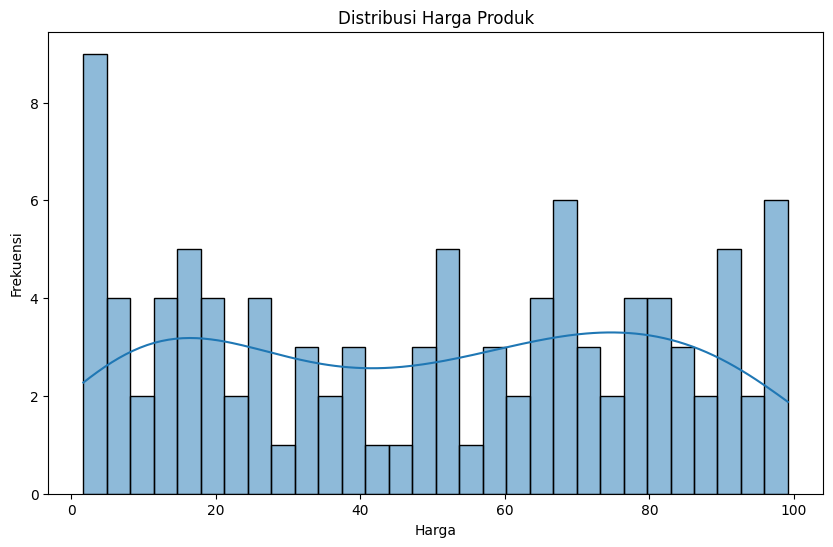

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(data['Price'], bins=30, kde=True)
plt.title('Distribusi Harga Produk')
plt.xlabel('Harga')
plt.ylabel('Frekuensi')
plt.show()

**12. Analisis Korelasi**

Heatmap dari matriks korelasi memberikan gambaran yang jelas tentang hubungan antar variabel dalam dataset. Dengan memvisualisasikan nilai korelasi, kita bisa dengan mudah mengidentifikasi variabel yang saling berhubungan, yang dapat membantu dalam pengambilan keputusan strategis seperti segmentasi pasar, penetapan harga, dan pengelolaan stok. Visualisasi ini juga memungkinkan kita untuk menemukan variabel yang mungkin memiliki dampak signifikan terhadap hasil yang diinginkan, seperti penjualan atau pendapatan.


In [ ]:
numeric_data = data.select_dtypes(include=[np.number])

# Menghitung matriks korelasi
correlation_matrix = numeric_data.corr()

# Membuat heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Matriks Korelasi')
plt.show()

NameError: name 'data' is not defined